# Solar PV Atlas
- How many solar PV facilities are in each county in North Carolina? 

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

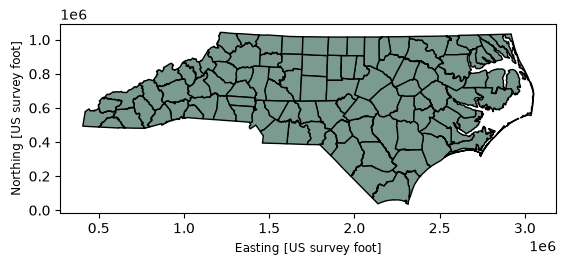

In [2]:
url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/"
url_county = "cb_2024_us_county_500k.zip"

counties = gpd.read_file(url_0 + url_county)

nc_counties = counties.loc[
    counties["STATEFP"] == "37"
].to_crs(6543).copy()

nc_counties.plot(edgecolor="black", facecolor="#7b9b90")

plt.show()

In [7]:
solar = gpd.read_file("solarPV.geojson")

In [8]:
solar.head()

,FID,Id,case_id,multi_poly,eia_id,p_state,p_county,ylat,xlong,p_area,...,p_azimuth,p_tilt,p_battery,p_cap_ac,p_cap_dc,p_type,p_agrivolt,p_comm,p_zscore,geometry
0,0,0,400011,single,2953,OK,Canadian,35.4774,-97.6764,50723,...,180.0,25.0,NaN,2.5,3.0,greenfield,non-agrivoltaic,community solar,-0.219022,"POLYGON ((-97.6768 35.47837, -97.67701 35.4783..."
1,1,0,407013,single,67406,NY,Erie,43.0168,-78.9779,77051,...,180.0,52.0,NaN,4.0,5.5,greenfield,non-agrivoltaic,community solar,-0.048823,"POLYGON ((-78.97948 43.01831, -78.97944 43.015..."
2,2,0,404351,single,64787,IL,Macoupin,39.4045,-90.0025,56943,...,25.0,NaN,NaN,2.0,3.0,greenfield,non-agrivoltaic,community solar,-0.308881,"POLYGON ((-90.00022 39.40521, -90.00142 39.405..."
3,3,0,404352,single,64788,NY,Greene,42.3708,-74.0406,40085,...,25.0,NaN,NaN,2.0,3.0,greenfield,non-agrivoltaic,community solar,-0.000703,"POLYGON ((-74.04066 42.3727, -74.04092 42.3727..."
4,4,0,404336,single,64734,IL,Stephenson,42.3804,-89.8412,55382,...,25.0,NaN,NaN,2.0,3.0,greenfield,non-agrivoltaic,community solar,-0.288227,"POLYGON ((-89.84004 42.38148, -89.84265 42.381..."


In [9]:
solar.columns

Index(['FID', 'Id', 'case_id', 'multi_poly', 'eia_id', 'p_state', 'p_county',
       'ylat', 'xlong', 'p_area', 'p_img_date', 'p_dig_conf', 'p_name',
       'p_year', 'p_pwr_reg', 'p_tech_pri', 'p_tech_sec', 'p_sys_type',
       'p_axis', 'p_azimuth', 'p_tilt', 'p_battery', 'p_cap_ac', 'p_cap_dc',
       'p_type', 'p_agrivolt', 'p_comm', 'p_zscore', 'geometry'],
      dtype='str')

In [10]:
nc_counties.crs

<Projected CRS: EPSG:6543>
Name: NAD83(2011) / North Carolina (ftUS)
Axis Info [cartesian]:
- X[east]: Easting (US survey foot)
- Y[north]: Northing (US survey foot)
Area of Use:
- name: United States (USA) - North Carolina - counties of Alamance; Alexander; Alleghany; Anson; Ashe; Avery; Beaufort; Bertie; Bladen; Brunswick; Buncombe; Burke; Cabarrus; Caldwell; Camden; Carteret; Caswell; Catawba; Chatham; Cherokee; Chowan; Clay; Cleveland; Columbus; Craven; Cumberland; Currituck; Dare; Davidson; Davie; Duplin; Durham; Edgecombe; Forsyth; Franklin; Gaston; Gates; Graham; Granville; Greene; Guilford; Halifax; Harnett; Haywood; Henderson; Hertford; Hoke; Hyde; Iredell; Jackson; Johnston; Jones; Lee; Lenoir; Lincoln; Macon; Madison; Martin; McDowell; Mecklenburg; Mitchell; Montgomery; Moore; Nash; New Hanover; Northampton; Onslow; Orange; Pamlico; Pasquotank; Pender; Perquimans; Person; Pitt; Polk; Randolph; Richmond; Robeson; Rockingham; Rowan; Rutherford; Sampson; Scotland; Stanly; Stoke

In [11]:
solar.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [12]:
solar = solar.to_crs(nc_counties.crs)

In [14]:
solar_nc = solar[solar["p_state"] == "NC"].copy()

solar_joined = gpd.sjoin(
    solar_nc,
    nc_counties,
    how="inner",
    predicate="intersects"
)

solar_counts = (
    solar_joined.groupby("NAME")
    .size()
    .reset_index(name="solar_count")
)

solar_counts.head()

,NAME,solar_count
0,Alamance,8
1,Alexander,3
2,Anson,8
3,Beaufort,11
4,Bertie,6


In [15]:
nc_atlas = nc_counties.merge(
    solar_counts,
    on="NAME",
    how="left"
)

nc_atlas["solar_count"] = (
    nc_atlas["solar_count"].fillna(0).astype(int)
)

nc_atlas[["NAME", "solar_count"]].head()

,NAME,solar_count
0,Columbus,18
1,Cherokee,3
2,Polk,0
3,Ashe,0
4,Dare,0


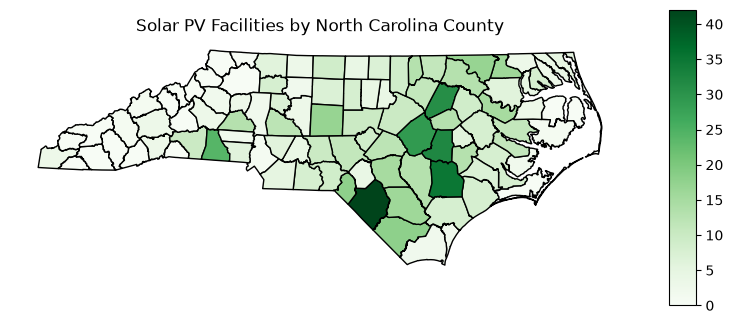

In [20]:
fig, ax = plt.subplots(figsize=(10, 7))

nc_atlas.plot(
    column="solar_count",
    cmap="Greens",
    legend=True,
    edgecolor="black",
    ax=ax
)

ax.set_title("Solar PV Facilities by North Carolina County")
ax.set_axis_off()

plt.show()

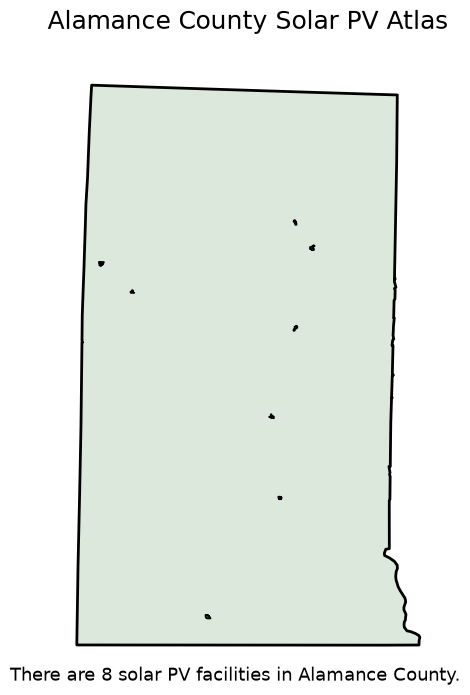

In [ ]:
# Code done with AI
county = nc_atlas[nc_atlas["NAME"] == "Alamance"]

county_name = "Alamance"
count = int(county["solar_count"].iloc[0])

# String concatenation required by your professor
sentence = (
    "There are " + str(count) +
    " solar PV facilities in " + county_name + " County."
)

fig, ax = plt.subplots(figsize=(10, 8))

# Plot the county boundary
county.plot(
    ax=ax,
    facecolor="#dce8dc",
    edgecolor="black",
    linewidth=2
)

# Plot solar facilities intersecting the county
county_solar = solar_joined[
    solar_joined["NAME"] == county_name
]

county_solar.plot(
    ax=ax,
    color="darkgreen",
    edgecolor="black",
    markersize=15
)

# Add the title and sentence
ax.set_title(
    county_name + " County Solar PV Atlas",
    fontsize=18,
    pad=20
)

fig.text(
    0.5, 0.10,
    sentence,
    ha="center",
    fontsize=13
)

ax.set_axis_off()

plt.show()

Creating Atlas with a For loop

In [22]:
#Code done with AI
from matplotlib.backends.backend_pdf import PdfPages

with PdfPages("NC_Solar_PV_Atlas.pdf") as pdf:

    for index, row in nc_atlas.iterrows():

        # Select the county
        county_name = row["NAME"]
        county = nc_atlas.loc[[index]]

        # Get the solar facility count
        count = int(row["solar_count"])

        # String concatenation
        sentence = (
            "There are " + str(count) +
            " solar PV facilities in " + county_name + " County."
        )

        # Select solar facilities for this county
        county_solar = solar_joined[
            solar_joined["NAME"] == county_name
        ]

        # Create the map
        fig, ax = plt.subplots(figsize=(10, 8))

        county.plot(
            ax=ax,
            facecolor="#dce8dc",
            edgecolor="black",
            linewidth=2
        )

        if not county_solar.empty:
            county_solar.plot(
                ax=ax,
                color="darkgreen",
                edgecolor="black"
            )

        # Add title
        ax.set_title(
            county_name + " County Solar PV Atlas",
            fontsize=18,
            pad=20
        )

        # Add result of spatial join
        fig.text(
            0.5, 0.10,
            sentence,
            ha="center",
            fontsize=13
        )

        ax.set_axis_off()

        # Save this page to PDF
        pdf.savefig(fig, bbox_inches="tight")

        # Close the figure before creating the next
        plt.close(fig)

print("Atlas successfully created!")

Atlas successfully created!
